# Age at first work
At what age do individuals produce their first work, and what is the best way to impute the year of the first work from the birth year?

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'
ENRICHED_DB_PATH = '../data/cultura/cultura_enriched_v3.2.duckdb'

MID_DECADE = 5
LIFETIME_LIMIT = 100
CENTURY = 100
FIRST_CENTURY, LAST_CENTURY = -800, 1800
LAST_YEAR = 1899
AGE_MIN, AGE_MAX = 10, 100
MIN_INDIVIDUALS = 10
SEED = 42
TRAIN_SHARE = 0.8
WITHIN = 10
RANDOM_AGE = (15, 60)
MODELS = {'century': ['century'], 'meta occupation': ['meta_occupation'], 'century × meta occupation': ['century', 'meta_occupation']}
MODEL_COLORS = {'random': LIGHT_GREY, 'global': GREY, 'century': BLUE, 'meta occupation': ORANGE, 'century × meta occupation': GREEN}
GROUPS = ['All', *OCCUPATION_COLORS, 'Other']
GROUP_COLORS = {'All': MAIN_LINE_COLOR, **OCCUPATION_COLORS, 'Other': GREY}

pl.Config.set_tbl_rows(40)
apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)
connection.execute(f"ATTACH '{ENRICHED_DB_PATH}' AS enriched (READ_ONLY)")

## Load the data
Cleaned work dates, as in notebook 03: a work's date is its inception, else its publication, precise to the year or decade (a decade counts as its middle year), and it must fit the individual's life (between birth and death, or birth + 100 when only the birth is known).

In [2]:
connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
clean_counts = connection.execute("SELECT count(DISTINCT qid) AS individuals, count(*) AS work_dates FROM clean_work").pl()
print(f"{clean_counts['individuals'][0]:,} individuals keep {clean_counts['work_dates'][0]:,} cleaned work dates")

584,893 individuals keep 9,481,624 cleaned work dates


### First work, birth and meta occupation
The main meta occupation is the most frequent one among the individual's occupations ("Other" when none).

In [3]:
first_works = connection.execute(f'''
    WITH ends AS (
        SELECT qid, any_value(birth_year) AS birth_year,
               min(CASE WHEN precision = 'decade' THEN year + {MID_DECADE} ELSE year END) AS first_year,
               count(*) AS works
        FROM clean_work
        WHERE birth_year IS NOT NULL
        GROUP BY qid
    ),
    held AS (
        SELECT individual.entity.qid AS qid,
               unnest(individual.occupation).entity.qid AS occupation_qid,
               generate_subscripts(individual.occupation, 1) AS position
        FROM individual
        JOIN ends ON ends.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN enriched.occupation AS occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    )
    SELECT ends.*, coalesce(main_meta_occupation.meta_occupation, 'Other') AS meta_occupation
    FROM ends
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = ends.qid
''').pl().with_columns(
    (pl.col('first_year') - pl.col('birth_year')).alias('first_age'),
    (pl.col('birth_year') // CENTURY * CENTURY).alias('century'),
)
assert first_works['qid'].is_unique().all()
print(f'{first_works.height:,} individuals with a birth year and at least one cleaned work')
first_works = first_works.filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY) & (pl.col('birth_year') <= LAST_YEAR))
print(f'{first_works.height:,} born from {FIRST_CENTURY} to {LAST_YEAR}')
first_works = first_works.filter(pl.col('first_age').is_between(AGE_MIN, AGE_MAX))
print(f'{first_works.height:,} with a first work between {AGE_MIN} and {AGE_MAX}: the group used below')
first_works.sample(5, seed=SEED)

557,730 individuals with a birth year and at least one cleaned work
114,425 born from -800 to 1899
113,156 with a first work between 10 and 100: the group used below


qid,birth_year,first_year,works,meta_occupation,first_age,century
str,i64,i64,i64,str,i64,i64
"""Q8012069""",1823,1855,3,"""Culture""",32,1800
"""Q5393723""",1888,1931,2,"""Culture""",43,1800
"""Q125448450""",1878,1922,1,"""Other""",44,1800
"""Q19368760""",1826,1875,1,"""Culture""",49,1800
"""Q23889106""",1899,1952,8,"""Culture""",53,1800


## 1. Which method best imputes the year of the first work?
A random 80% of the group learns the mean age at first work (train); for the other 20% (test), the first work is imputed as birth year + that mean, and is good when within 10 years of the true first work. A group with fewer than 10 training individuals takes the global mean. The century is the century of birth. Models:

- **random**: an age drawn at random between 15 and 60.
- **global**: all training individuals.
- **century**, **meta occupation**, **century × meta occupation**: the training individuals of the same group.

In [4]:
shuffled = first_works.sort('qid').sample(fraction=1, shuffle=True, seed=SEED)
cut = int(TRAIN_SHARE * shuffled.height)
train, test = shuffled[:cut], shuffled[cut:]
assert train.height + test.height == first_works.height and test.join(train, on='qid').height == 0
global_mean = train['first_age'].mean()
print(f'train: {train.height:,}, test: {test.height:,}, global mean: {global_mean:.1f} years')

base = test.select('qid', 'century', 'meta_occupation', 'birth_year', 'first_year')
models = [
    base.with_columns(pl.lit('random').alias('model'), pl.Series('age', np.random.default_rng(SEED).integers(RANDOM_AGE[0], RANDOM_AGE[1] + 1, base.height)).cast(pl.Float64)),
    base.with_columns(pl.lit('global').alias('model'), pl.lit(global_mean).alias('age')),
]
for model, keys in MODELS.items():
    means = train.group_by(keys).agg(pl.len().alias('train individuals'), pl.col('first_age').mean().alias('age')).filter(pl.col('train individuals') >= MIN_INDIVIDUALS)
    joined = base.join(means, on=keys, how='left')
    print(f"{model}: {joined['age'].null_count():,} test individuals take the global mean")
    models.append(joined.select(*base.columns, pl.lit(model).alias('model'), pl.col('age').fill_null(global_mean)))
imputed = pl.concat(models).with_columns(
    (pl.col('birth_year') + pl.col('age').round()).cast(pl.Int64).alias('imputed first year'),
).with_columns((pl.col('imputed first year') - pl.col('first_year')).alias('error'))
imputed.sample(5, seed=SEED)

train: 90,524, test: 22,632, global mean: 39.3 years
century: 4 test individuals take the global mean
meta occupation: 0 test individuals take the global mean
century × meta occupation: 62 test individuals take the global mean


qid,century,meta_occupation,birth_year,first_year,model,age,imputed first year,error
str,i64,str,i64,i64,str,f64,i64,i64
"""Q85517""",1800,"""Culture""",1871,1922,"""century × meta occupation""",37.37676,1908,-14
"""Q11703497""",1800,"""Discovery/Science""",1840,1878,"""global""",39.313243,1879,1
"""Q774020""",1800,"""Culture""",1886,1919,"""century × meta occupation""",37.37676,1923,4
"""Q5393669""",1800,"""Culture""",1869,1898,"""meta occupation""",37.03673,1906,8
"""Q1389068""",1800,"""Culture""",1857,1881,"""meta occupation""",37.03673,1894,13


### Table: accuracy
Each score is computed in every century of birth (with at least 10 test individuals), then averaged with every century weighing the same.

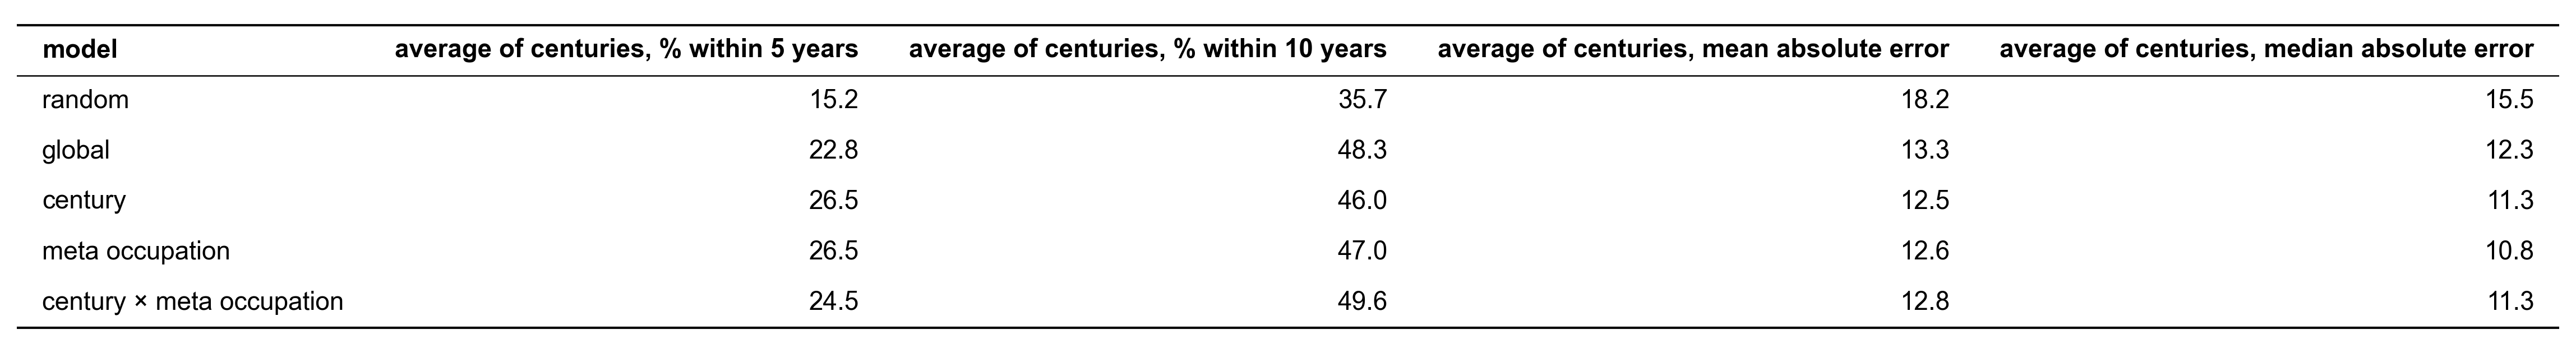

In [5]:
per_century = (
    imputed.group_by('model', 'century', maintain_order=True).agg(
        pl.len().alias('individuals'),
        *[(100 * (pl.col('error').abs() <= years).mean()).alias(f'% within {years} years') for years in (5, WITHIN)],
        pl.col('error').abs().mean().alias('mean absolute error'),
        pl.col('error').abs().median().alias('median absolute error'),
    )
    .filter(pl.col('individuals') >= MIN_INDIVIDUALS)
    .sort('century')
)
model_result = (
    per_century.group_by('model')
    .agg(pl.col('% within 5 years', f'% within {WITHIN} years', 'mean absolute error', 'median absolute error').mean().name.prefix('average of centuries, '))
    .sort(pl.col('model').replace_strict(list(MODEL_COLORS), list(range(len(MODEL_COLORS)))))
)
show_table(model_result, decimals=1)

### Figure: % of first works within 10 years per century of birth
Number of test individuals above each century.

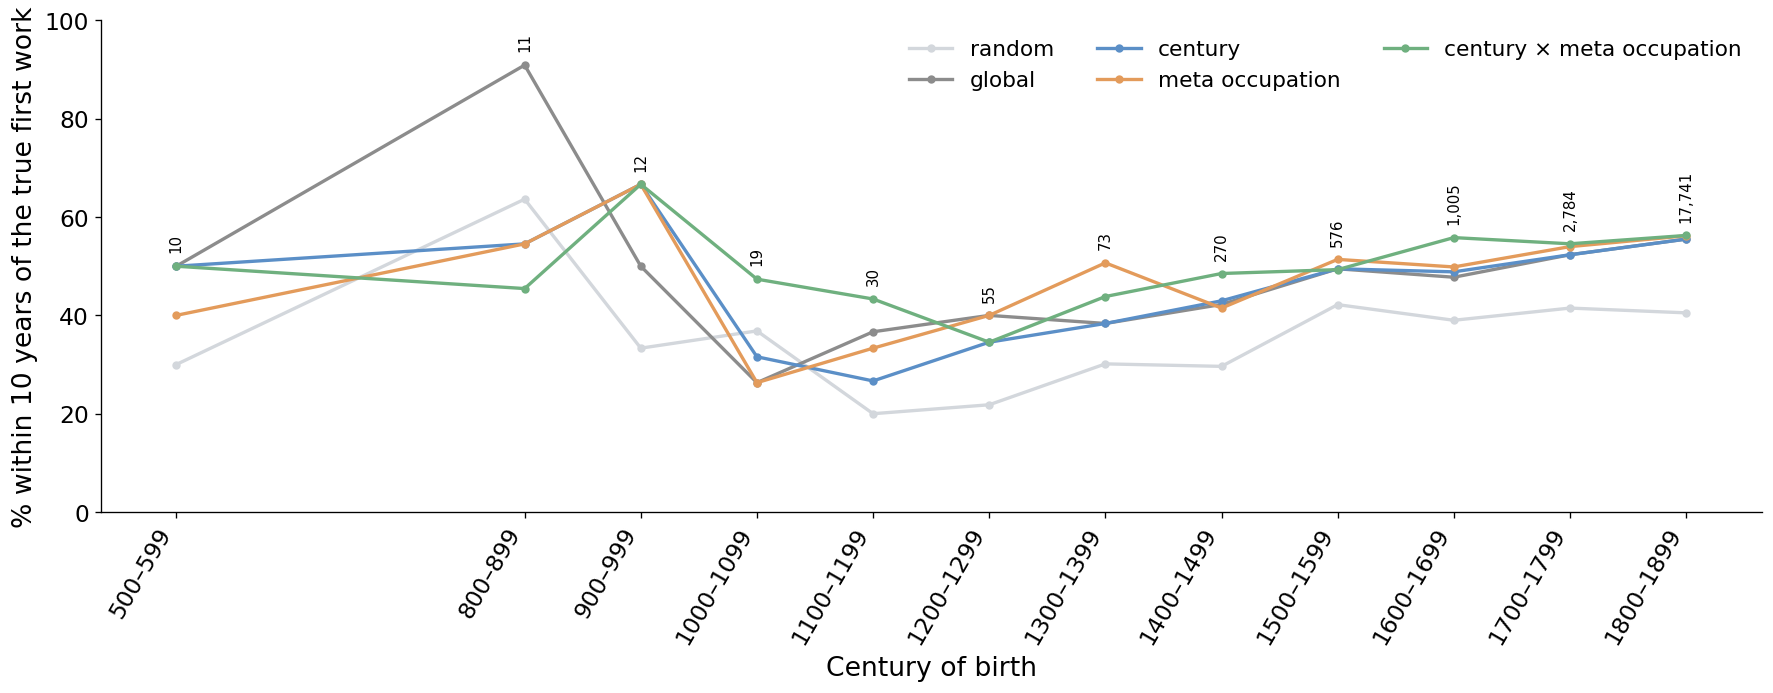

In [6]:
def century_label(start):
    end = min(start + CENTURY - 1, LAST_YEAR)
    return f'{-start}–{-end} BC' if end < 0 else f'{start}–{end}'


fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for model, color in MODEL_COLORS.items():
    rows = per_century.filter(pl.col('model') == model)
    ax.plot(rows['century'], rows[f'% within {WITHIN} years'], color=color, linewidth=2, marker='o', markersize=4, label=model)
tested = per_century.group_by('century').agg(pl.col('individuals').first(), pl.col(f'% within {WITHIN} years').max()).sort('century')
for century, tested_individuals, top in tested.iter_rows():
    ax.annotate(f'{tested_individuals:,}', (century, top), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, rotation=90, va='bottom')
ax.set_xticks(tested['century'].to_list())
ax.set_xticklabels([century_label(start) for start in tested['century']], rotation=60, ha='right', fontsize=14)
ax.set_ylim(0, 100)
ax.set_ylabel(f'% within {WITHIN} years of the true first work')
ax.set_xlabel('Century of birth')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right', ncols=3)
plt.tight_layout()
plt.show()

## 2. Age at first work
Median in colour, quartiles in grey, mean as a diamond.

In [7]:
def box_stats(frame, by):
    return (
        frame.group_by(by)
        .agg(
            pl.len().alias('individuals'),
            pl.col('first_age').quantile(0.25, 'linear').alias('low'),
            pl.col('first_age').median().alias('median'),
            pl.col('first_age').quantile(0.75, 'linear').alias('high'),
            pl.col('first_age').mean().round(1).alias('mean'),
        )
        .filter(pl.col('individuals') >= MIN_INDIVIDUALS)
        .sort(by)
    )


def draw_boxes(ax, values, positions, width, color, stats, mean_labels=True):
    ax.boxplot(values, positions=positions, widths=width, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color),
               medianprops=dict(color=color, linewidth=2), whiskerprops=dict(color=color), capprops=dict(color=color))
    for x, row in zip(positions, stats.iter_rows(named=True)):
        ax.annotate(f"{row['median']:.0f}", (x + width * 0.55, row['median']), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE, color=color)
        for q in (row['low'], row['high']):
            ax.annotate(f'{q:.0f}', (x + width * 0.55, q), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)
        ax.plot(x, row['mean'], marker='D', markersize=5, color='white', markeredgecolor=TEXT, zorder=3)
        if mean_labels:
            ax.annotate(f"{row['mean']:.1f}", (x - width * 0.55, row['mean']), ha='right', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=TEXT)


def plot_centuries(ax, frame, color):
    stats = box_stats(frame, 'century')
    starts = stats['century'].to_list()
    x = np.array(starts) + CENTURY / 2
    draw_boxes(ax, [frame.filter(pl.col('century') == start)['first_age'].to_numpy() for start in starts], x, CENTURY * 0.5, color, stats, mean_labels=False)
    ax.set_xticks(x)
    ax.set_xticklabels([century_label(start) for start in starts], rotation=45, ha='right')
    ax.set_xlim(starts[0] - CENTURY / 2, starts[-1] + 1.5 * CENTURY)
    ax.set_ylim(0, AGE_MAX + 25)
    ax.set_yticks(range(0, AGE_MAX + 1, 20))
    ax.grid(axis='y')
    for xi, n in zip(x, stats['individuals']):
        ax.text(xi, AGE_MAX + 3, f'{n:,}', rotation=90, ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)

### Table: age at first work, all individuals and by meta occupation

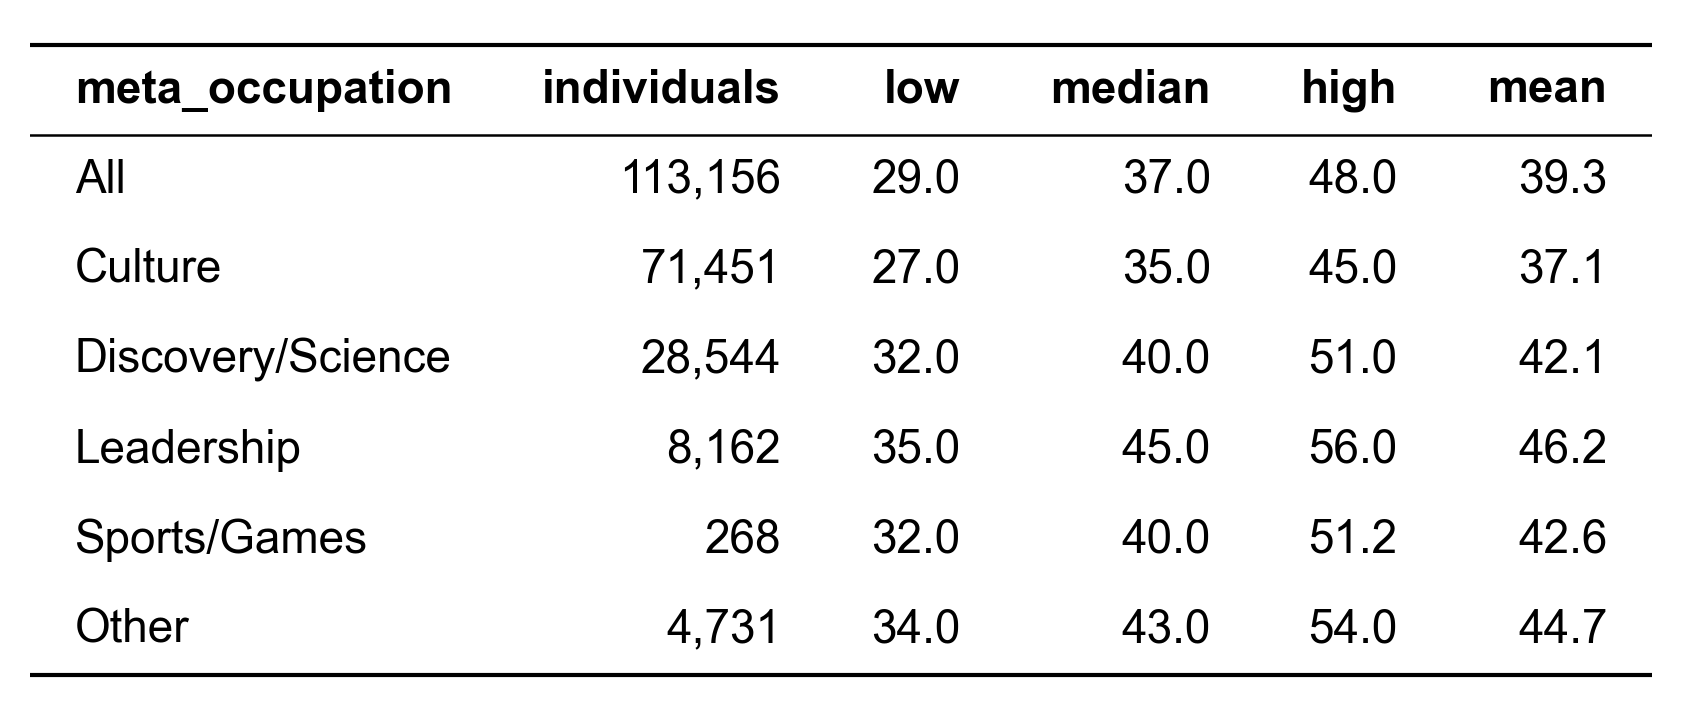

In [8]:
group_stats = pl.concat([
    box_stats(first_works.with_columns(pl.lit('All').alias('meta_occupation')), 'meta_occupation'),
    box_stats(first_works, 'meta_occupation'),
]).sort(pl.col('meta_occupation').replace_strict(GROUPS, list(range(len(GROUPS)))))
show_table(group_stats, decimals=1)

### Figure: age at first work, all individuals and by meta occupation

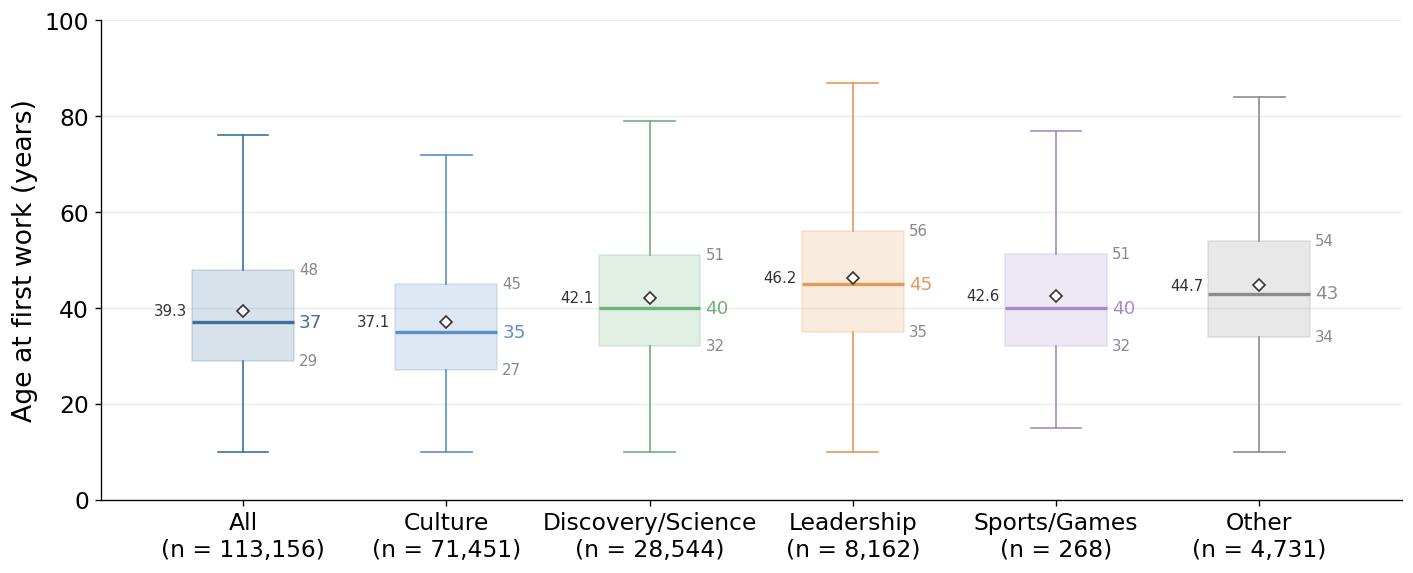

In [9]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, row in enumerate(group_stats.iter_rows(named=True)):
    group = row['meta_occupation']
    values = first_works if group == 'All' else first_works.filter(pl.col('meta_occupation') == group)
    draw_boxes(ax, [values['first_age'].to_numpy()], [i], 0.5, GROUP_COLORS[group], group_stats[i])
ax.set_xticks(range(group_stats.height))
ax.set_xticklabels([f"{row['meta_occupation']}\n(n = {row['individuals']:,})" for row in group_stats.iter_rows(named=True)])
ax.set_xlim(-0.7, group_stats.height - 0.3)
ax.set_ylim(0, AGE_MAX)
ax.set_ylabel('Age at first work (years)')
ax.grid(axis='y')
plt.tight_layout()
plt.show()

### Table: age at first work per century of birth

In [10]:
box_stats(first_works, 'century')

century,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-500,11,34.0,39.0,48.5,40.7
-400,16,31.75,42.5,52.25,43.1
-100,16,34.0,43.0,57.5,46.4
0,16,42.25,51.5,58.25,48.4
100,14,35.5,40.5,47.5,45.9
200,15,35.0,41.0,52.5,43.2
300,27,33.0,39.0,48.5,43.3
400,16,33.75,42.0,51.75,43.8
500,36,41.25,53.0,60.75,51.2


### Figure: age at first work per century of birth
Individuals above each century; centuries with fewer than 10 individuals are left out.

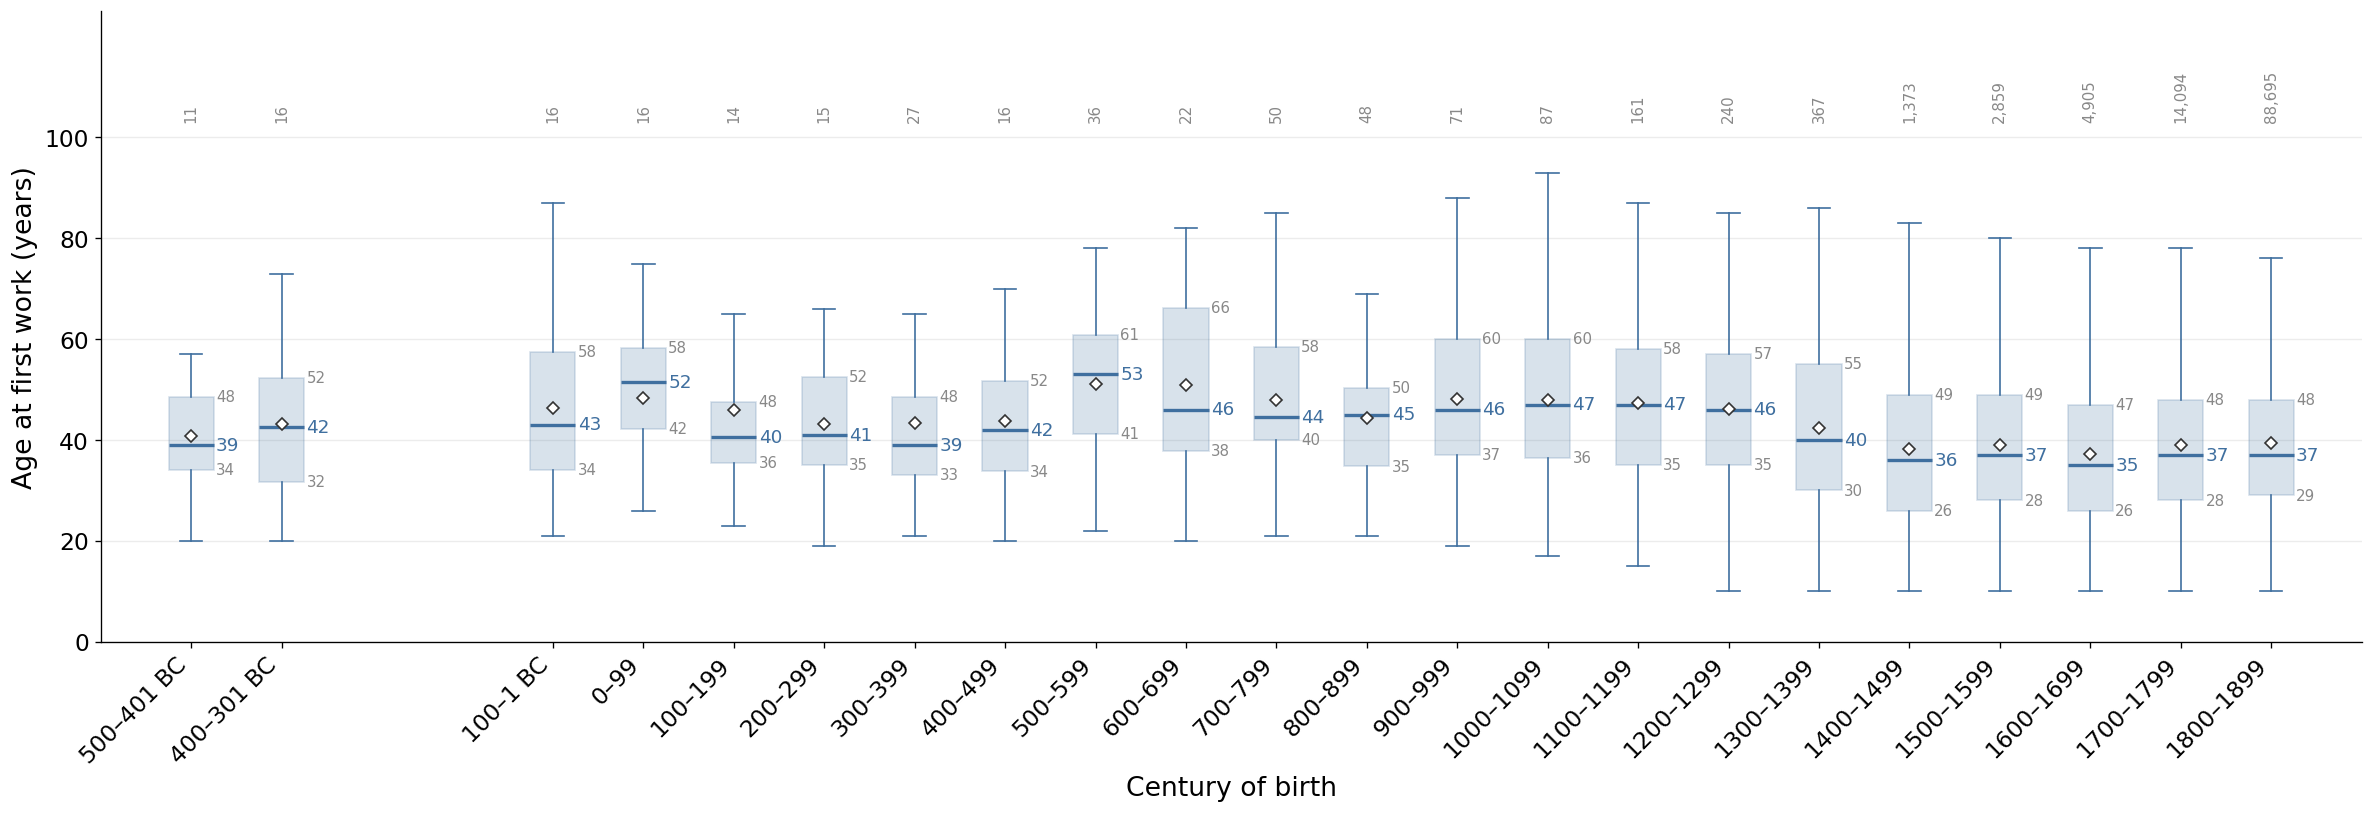

In [11]:
fig, ax = plt.subplots(figsize=(20, 7))
plot_centuries(ax, first_works, MAIN_LINE_COLOR)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Age at first work (years)')
plt.tight_layout()
plt.show()

### Table: age at first work per century of birth and meta occupation
The values used by the century × meta occupation model.

In [12]:
box_stats(first_works.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), ['meta_occupation', 'century'])

meta_occupation,century,individuals,low,median,high,mean
str,i64,u32,f64,f64,f64,f64
"""Culture""",500,12,36.5,54.0,61.25,50.2
"""Culture""",700,18,36.25,43.0,47.25,42.8
"""Culture""",800,10,33.25,43.0,45.0,41.4
"""Culture""",900,20,34.25,41.5,57.75,47.0
"""Culture""",1000,28,32.0,44.5,54.25,44.1
"""Culture""",1100,69,32.0,40.0,55.0,43.4
"""Culture""",1200,109,33.0,44.0,55.0,44.1
"""Culture""",1300,216,27.0,37.0,49.25,39.4
"""Culture""",1400,974,25.0,32.5,42.0,34.6


### Figure: age at first work per century of birth, by meta occupation

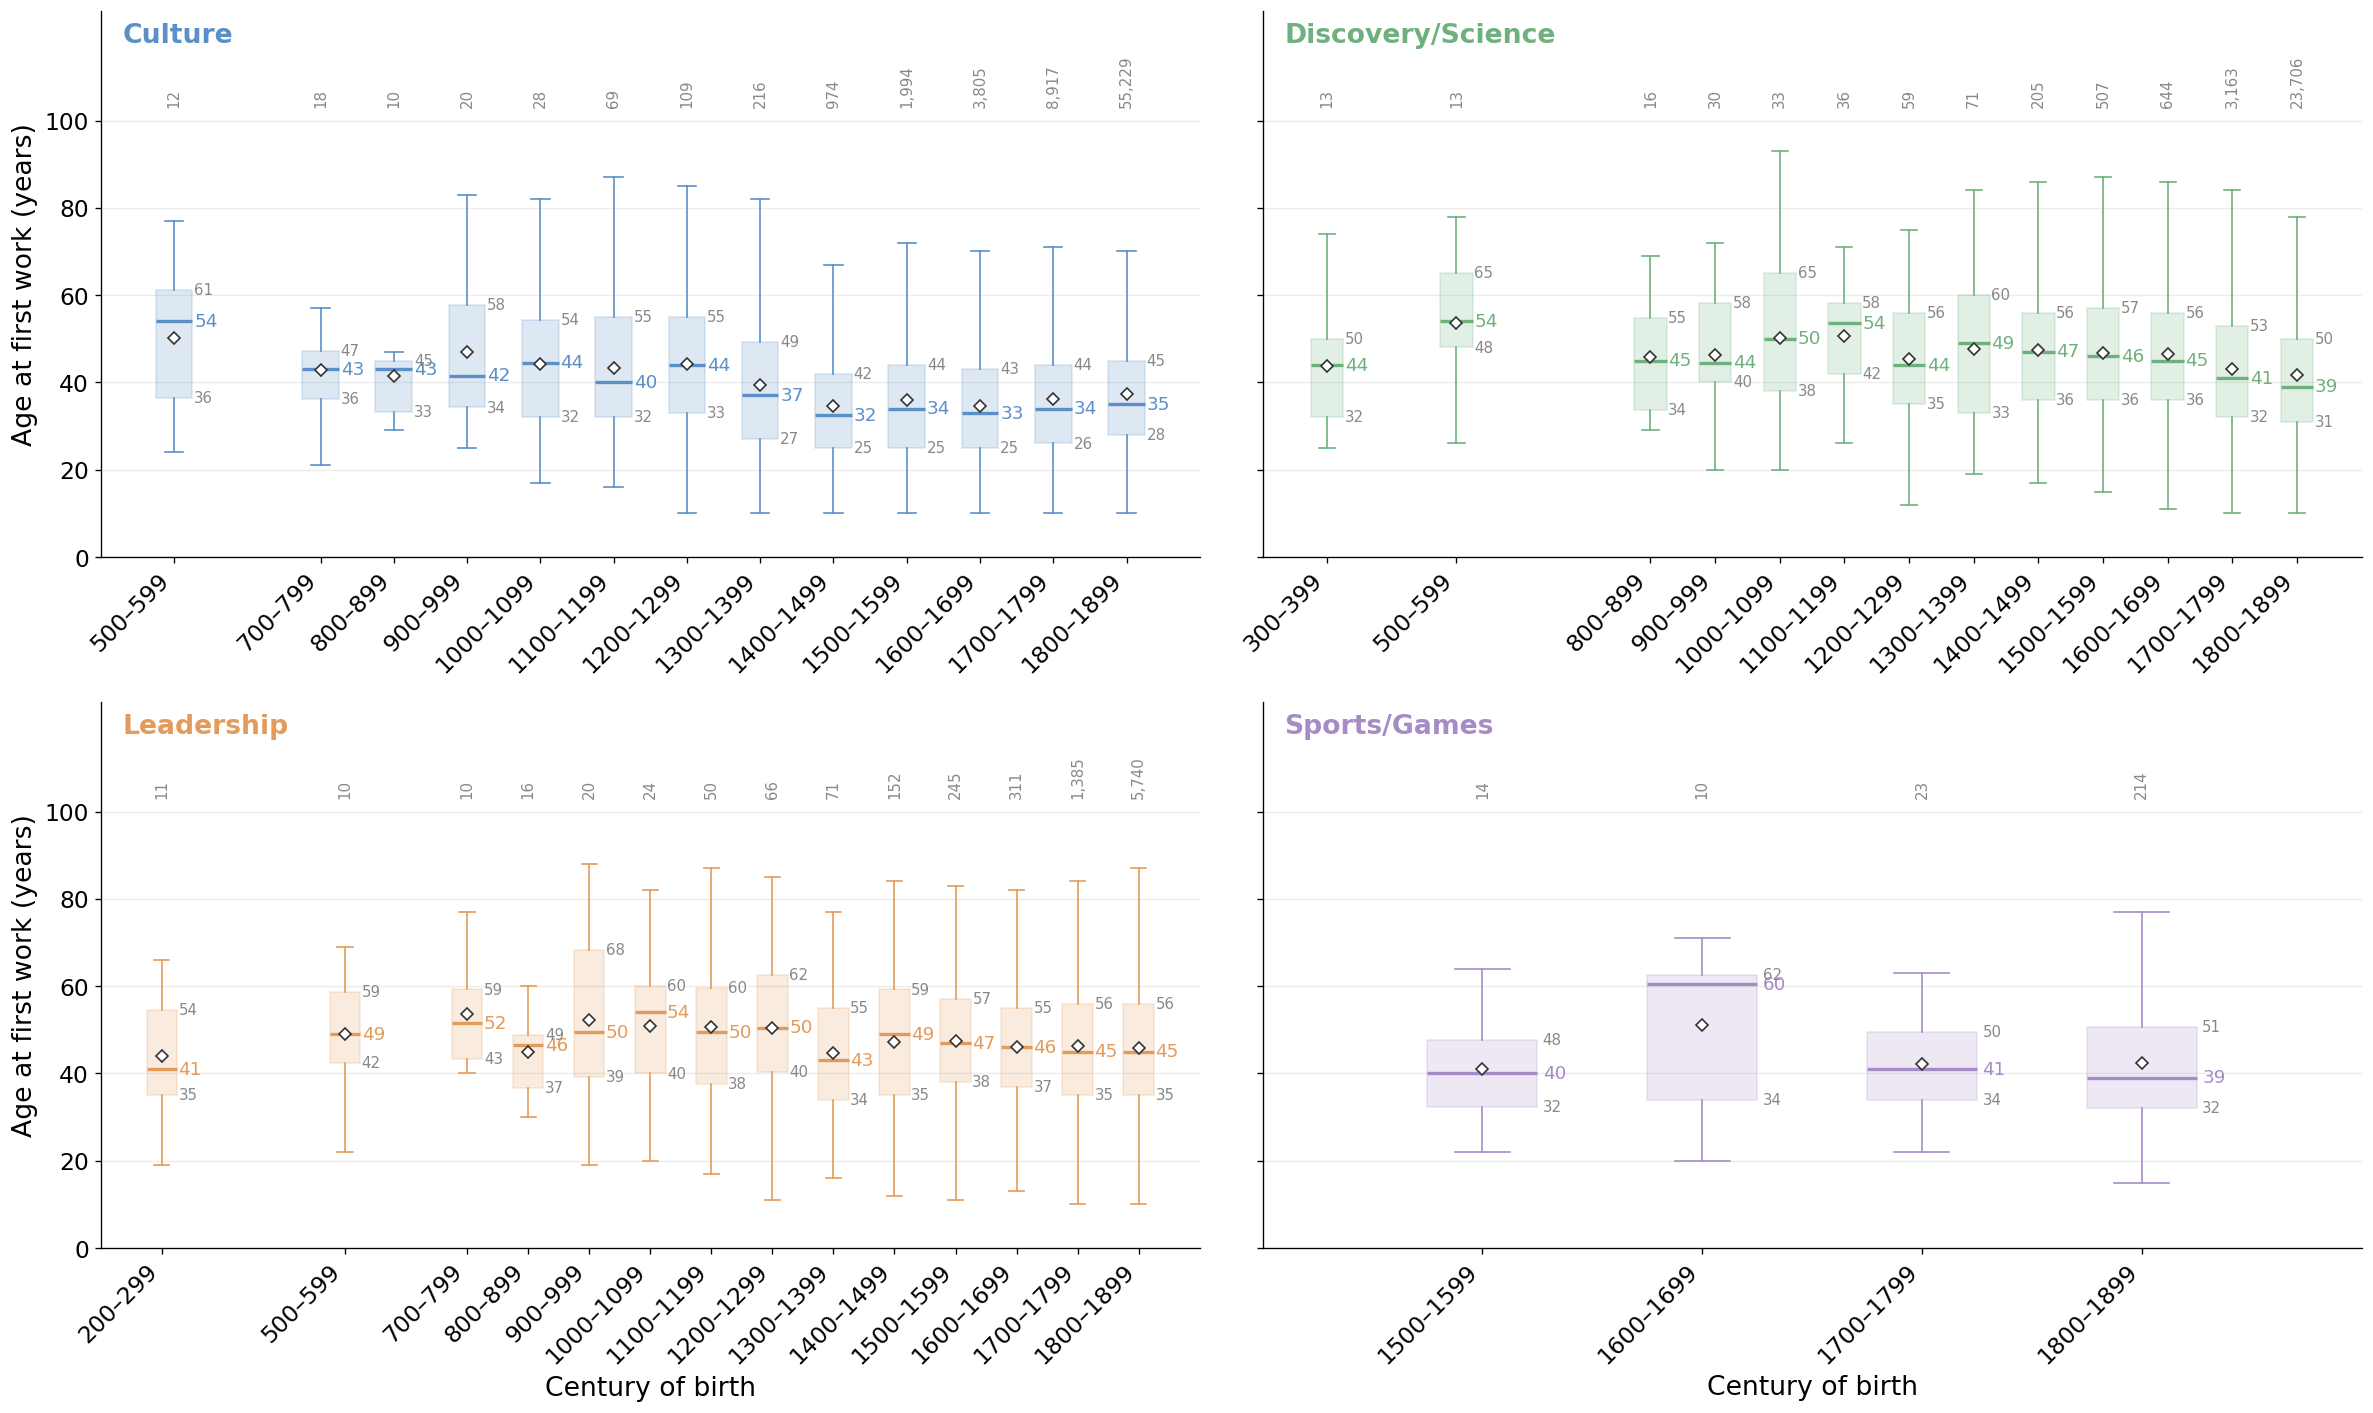

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharey=True)
for ax, (occupation, color) in zip(axes.flat, OCCUPATION_COLORS.items()):
    ax.text(0.02, 0.98, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=color, va='top', fontweight='bold')
    plot_centuries(ax, first_works.filter(pl.col('meta_occupation') == occupation), color)
for ax in axes[-1, :]:
    ax.set_xlabel('Century of birth')
for ax in axes[:, 0]:
    ax.set_ylabel('Age at first work (years)')
plt.tight_layout()
plt.show()